In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import panel as pn
from bokeh.models import ColumnDataSource, HoverTool, Range1d
from bokeh.plotting import figure

pn.extension("tabulator")

In [3]:
def rhob_from_apparent_porosity(apparent_porosity, rho_matrix=2.65, rho_fluid=1.0):
    return rho_matrix * (1 - apparent_porosity) + rho_fluid * apparent_porosity

In [4]:
def nd_triangle(
    nphi,
    rhob=None,
    shale_point=None,
    matrix_point=(0.0, 2.65),
    fluid_point=(1.0, 1.0),
    phi_sh=None,
    plot=False,
    number_format=".3f",
):
    """
    Compute shale and porosity fractions from a neutron-density triangle.
    End-members in (NPHI, RHOB) space:
        matrix : clean matrix           (default quartz: NPHI = 0.00, RHOB = 2.65)
        fluid  : fluid-filled pore      (default water:  NPHI = 1.00, RHOB = 1.00)
        shale  : wet shale (user input)
    
    Each log point is treated as a linear mix of the three end-members.
    Solving for the volume fractions = computing barycentric coordinates:
        NPHI = Vmatrix*phi_m + Vfluid*phi_f + Vshale*phi_sh
        RHOB = Vmatrix*rho_m + Vfluid*rho_f + Vshale*rho_sh
        1    = Vmatrix       + Vfluid       + Vshale
 
    Usage:
    ------
    Single point: nd_triangle(0.25, 2.20, shale_point=(0.40, 2.45))
    Multiple points: nd_triangle([0.25, 0.30], [2.20, 2.10], shale_point=(0.40, 2.45))
        or nd_triangle([(0.25, 2.20), (0.30, 2.10)], shale_point=(0.40, 2.45))

    Parameters:
    -----------
    nphi, rhob : float
        Log point. NPHI in v/v (on the same lithology scale as matrix_point), RHOB in g/cc.
    shale_point : (nphi_sh, rhob_sh)
        Wet-shale end-member, e.g. (0.38, 2.45).
    matrix_point : (nphi_ma, rhob_ma)
        Clean matrix end-member. Default: quartz on a sandstone scale.
    fluid_point : (nphi_f, rhob_f)
        Pore-fluid end-member. Default: fresh water.
    phi_sh : float, optional
        Total porosity of the shale (bound water). Default: density porosity of the shale point, (rho_ma - rho_sh) / (rho_ma - rho_f).
    plot : bool
        If True, draw the triangle and the point (needs matplotlib).

    Returns
    -------
    dict with
        v_matrix, v_shale, v_fluid : volume fractions (sum to 1)
        phi_effective : porosity of the non-shale part (= v_fluid)
        phi_total     : v_fluid + v_shale*phi_sh
        inside        : True if the point lies inside the triangle else False
        raw_fractions : (matrix, fluid, shale)        
    """

    if shale_point is None:
        raise ValueError("shale_point is required.")

    scalar_input = False
    if rhob is None:
        points = np.asarray(nphi, dtype=float)
        if points.ndim == 1 and points.size == 2:
            points = points.reshape(1, 2)
            scalar_input = True
        elif points.ndim == 2 and points.shape[1] == 2:
            scalar_input = len(points) == 1
        else:
            raise ValueError("When rhob is omitted, pass a single (nphi, rhob) pair or an array of pairs.")
        nphi_values = points[:, 0]
        rhob_values = points[:, 1]

    else:
        nphi_values, rhob_values = np.broadcast_arrays(np.asarray(nphi, dtype=float), np.asarray(rhob, dtype=float))
        scalar_input = (np.ndim(nphi) == 0 and np.ndim(rhob) == 0)
        nphi_values = nphi_values.ravel()
        rhob_values = rhob_values.ravel()

    nphi_ma, rho_ma = matrix_point
    nphi_f, rho_f = fluid_point
    nphi_sh, rho_sh = shale_point

    A = np.array([[nphi_ma, nphi_f, nphi_sh], [rho_ma, rho_f, rho_sh], [1.0, 1.0, 1.0]])
    detA = np.linalg.det(A)

    if abs(detA) < 1e-12:
        raise ValueError("End-members are collinear; the triangle is degenerate.")

    b = np.column_stack((nphi_values, rhob_values, np.ones_like(nphi_values)))
    Ainv = np.linalg.inv(A)
    raw_fractions = (Ainv @ b.T).T


    if phi_sh is None:
        phi_sh = (rho_ma - rho_sh) / (rho_ma - rho_f)

    results = []

    for raw in raw_fractions:
        v_ma, v_f, v_sh = raw
        inside = bool(np.all(raw >= -1e-9))
        clipped = np.clip(raw, 0.0, 1.0)
        s = clipped.sum()
        if s > 0:
            clipped /= s
        v_ma_c, v_f_c, v_sh_c = clipped

        results.append(
            {
                "Vmatrix": float(v_ma_c),
                "Vshale": float(v_sh_c),
                "Vfluid": float(v_f_c),
                "PHIE": float(v_f_c),
                "PHIT": float(v_f_c + v_sh_c * phi_sh),
                "PHISH": float(phi_sh),
                "inside?": inside,
                "fractions_raw": tuple(float(v) for v in raw),
            }
        )

    if plot:
        fig, ax = plt.subplots(figsize=(6, 6))
        triangle = np.array([matrix_point, fluid_point, shale_point, matrix_point])
        ax.plot(triangle[:, 0], triangle[:, 1], "k-", lw=1.5)

        for point, label in zip((matrix_point, fluid_point, shale_point), ("Matrix Point", "Fluid Point", "Shale Point")):
            ax.plot(*point, "ko")
            ax.annotate(label, point, textcoords="offset points", xytext=(6, 6))

        ax.scatter(nphi_values, rhob_values, marker="x", color="red", label="Arbitrary point(s)")

        for i, (x, y) in enumerate(zip(nphi_values, rhob_values), start=1):
            ax.annotate(str(i), (x, y), textcoords="offset points", xytext=(10, 0), ha="left", va="center")

        ax.set_xlabel("NPHI (v/v)")
        ax.set_ylabel("RHOB (g/cc)")
        ax.invert_yaxis()
        ax.grid(alpha=0.3)
        ax.legend()
        ax.set_title(f"NPHI/RHOB triangle ({len(results)} point(s))")

        plt.show()

    return results[0] if scalar_input else results

In [ ]:
nd_points_input = pn.widgets.TextAreaInput(
    name="Log points: NPHI, RHOB (one pair per line)",
    value="0.40, 2.25\n0.828, 1.50",
    height=357,
)
nd_shale_nphi = pn.widgets.FloatSlider(
    name="Shale Point NPHI (v/v)", start=0.0, end=1.0, value=0.57, step=0.001
)
nd_shale_rhob = pn.widgets.FloatSlider(
    name="Shale Point RHOB (g/cc)",
    start=1.0,
    end=2.65,
    value=rhob_from_apparent_porosity(0.24),
    step=0.001,
)

nd_checkbox = pn.widgets.Checkbox(
    name="Allow change of fluid and matrix points", value=False
)

nd_matrix_nphi = pn.widgets.FloatSlider(
    name="Matrix Point NPHI (v/v)", start=0.0, end=0.05, value=0.0, step=0.001
)
nd_matrix_rhob = pn.widgets.FloatSlider(
    name="Matrix Point RHOB (g/cc)",
    start=2.60,
    end=3.00,
    value=rhob_from_apparent_porosity(0.0),
    step=0.001,
)
nd_fluid_nphi = pn.widgets.FloatSlider(
    name="Fluid Point NPHI (v/v)", start=0.80, end=1.20, value=1.0, step=0.001
)
nd_fluid_rhob = pn.widgets.FloatSlider(
    name="Fluid Point RHOB (g/cc)", start=0.8, end=1.2, value=1.0, step=0.001
)

nd_end_member_sliders = (
    nd_matrix_nphi,
    nd_matrix_rhob,
    nd_fluid_nphi,
    nd_fluid_rhob,
)


def nd_update_slider_state(event=None):
    for slider in nd_end_member_sliders:
        slider.disabled = not nd_checkbox.value


nd_checkbox.param.watch(nd_update_slider_state, "value")
nd_update_slider_state()

nd_end_member_controls = pn.Column(
    nd_checkbox,
    nd_matrix_nphi,
    nd_matrix_rhob,
    nd_fluid_nphi,
    nd_fluid_rhob,
    width=300,
)


def nd_dynamic_view(
    points_text,
    shale_nphi,
    shale_rhob,
    matrix_nphi,
    matrix_rhob,
    fluid_nphi,
    fluid_rhob,
    allow_change,
):
    try:
        points = np.asarray(
            [
                [float(value) for value in line.replace(",", " ").split()]
                for line in points_text.splitlines()
                if line.strip()
            ],
            dtype=float,
        )
        if points.ndim != 2 or points.shape[1] != 2:
            raise ValueError("Enter one NPHI, RHOB pair per line (comma or space separated).")
        if not np.isfinite(points).all():
            raise ValueError("Log points must contain finite numbers.")

        shale = (shale_nphi, shale_rhob)
        matrix = (matrix_nphi, matrix_rhob) if allow_change else (0.0, 2.65)
        fluid = (fluid_nphi, fluid_rhob) if allow_change else (1.0, 1.0)

        results = nd_triangle(
            points,
            shale_point=shale,
            matrix_point=matrix,
            fluid_point=fluid,
            plot=False,
        )
        if isinstance(results, dict):
            results = [results]

        table = pd.DataFrame(results)
        table.insert(0, "Point", np.arange(1, len(points) + 1))
        table.insert(1, "NPHI", points[:, 0])
        table.insert(2, "RHOB", points[:, 1])
        table["inside"] = table.pop("inside?")
        raw = np.asarray(table.pop("fractions_raw").tolist())
        for index, name in enumerate(("Raw matrix", "Raw fluid", "Raw shale")):
            table[name] = raw[:, index]

        source = ColumnDataSource(table)
        vertices = np.array([matrix, fluid, shale])
        extent = np.vstack((vertices, points))
        low = extent.min(axis=0)
        high = extent.max(axis=0)
        padding = np.maximum((high - low) * 0.1, [0.05, 0.05])

        chart = figure(
            title="Neutron vs Density",
            x_axis_label="NPHI (v/v)",
            y_axis_label="RHOB (g/cc)",
            x_range=Range1d(low[0] - padding[0], high[0] + padding[0]),
            y_range=Range1d(high[1] + padding[1], low[1] - padding[1]),
            width=500,
            height=500,
            tools="pan,wheel_zoom,box_zoom,reset,save",
        )

        triangle = np.vstack((vertices, vertices[0]))
        chart.line(triangle[:, 0], triangle[:, 1], color="black")
        chart.scatter(vertices[:, 0], vertices[:, 1], size=9, color="black")
        chart.text(
            vertices[:, 0],
            vertices[:, 1],
            text=["Matrix", "Fluid", "Shale"],
            x_offset=8,
            y_offset=8,
        )

        markers = chart.scatter(
            "NPHI", "RHOB", source=source, marker="x", size=8, color="firebrick"
        )
        chart.add_tools(
            HoverTool(
                renderers=[markers],
                tooltips=[
                    ("Point", "@Point"),
                    ("NPHI", "@NPHI{0.000}"),
                    ("RHOB", "@RHOB{0.000}"),
                    ("Vmatrix", "@Vmatrix{0.000}"),
                    ("Vshale", "@Vshale{0.000}"),
                    ("Vfluid / PHIE", "@PHIE{0.000}"),
                    ("PHIT", "@PHIT{0.000}"),
                    ("PHISH", "@PHISH{0.000}"),
                    ("Inside triangle", "@inside"),
                ],
            )
        )

        grid = pn.widgets.Tabulator(
            table.round(4),
            show_index=False,
            disabled=True,
            sizing_mode="stretch_width",
            height=300,
        )

        plot_and_controls = pn.Row(
            pn.pane.Bokeh(chart),
            nd_end_member_controls,
            align="start",
            sizing_mode="stretch_width",
        )

        return pn.Column(
            plot_and_controls,
            grid,
            pn.pane.Markdown(
                "Outside-triangle fractions are clipped and normalized "
                "by `nd_triangle`; raw fractions are included in the table."
            ),
            sizing_mode="stretch_width",
        )
    except (ValueError, TypeError, np.linalg.LinAlgError) as exc:
        return pn.pane.Alert(str(exc), alert_type="warning")


nd_dashboard = pn.Column(
    pn.pane.Markdown(
        "## Ternary plot to graphically resolve for shale volume, "
        "sand fraction and porosity simultaneously",
        styles={"color": "brown"},
    ),
    pn.Row(
        nd_controls,
        pn.bind(
            nd_dynamic_view,
            nd_points_input,
            nd_shale_nphi,
            nd_shale_rhob,
            nd_matrix_nphi,
            nd_matrix_rhob,
            nd_fluid_nphi,
            nd_fluid_rhob,
            nd_checkbox,
        ),
        sizing_mode="stretch_width",
        align="start",
    ),
    sizing_mode="stretch_width",
)

nd_dashboard.show()

Launching server at http://localhost:63803


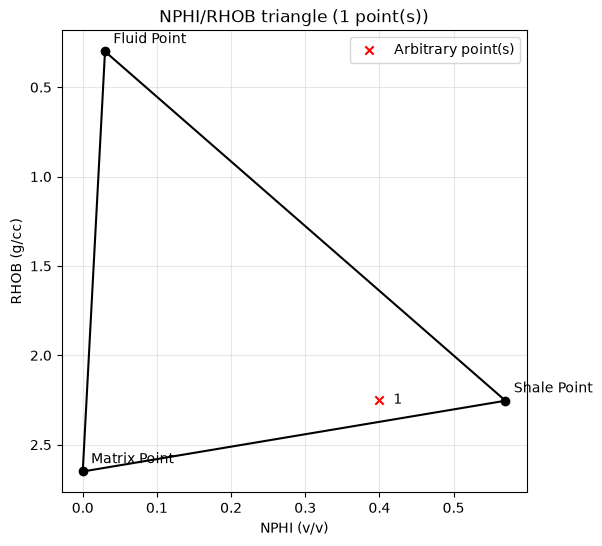

Vmatrix        0.249
Vshale         0.699
Vfluid         0.052
PHIE           0.052
PHIT           0.170
PHISH          0.169
inside?        True
fractions_raw  (0.24858016601135866, 0.05242463958060273, 0.6989951944080386)


In [6]:
number_format = ".3f"
out = nd_triangle(nphi=0.4, rhob=2.25, shale_point=(0.57, rhob_from_apparent_porosity(0.24)), plot=True, fluid_point=(0.03, 0.3))
for k, v in out.items():
    print(f"{k:14s} {format(v, number_format) if isinstance(v, float) else v}")

In [ ]:
out = nd_triangle(nphi=0.4, rhob=2.25, shale_point=(0.57, rhob_from_apparent_porosity(0.24)), plot=True)
for k, v in out.items():
    print(f"{k:14s} {format(v, number_format) if isinstance(v, float) else v}")

In [ ]:
rhob_from_apparent_porosity(0.24)

In [ ]:
out = nd_triangle(nphi=0.828, rhob=1.5, shale_point=(0.57, rhob_from_apparent_porosity(0.24)), plot=True)
for k, v in out.items():
    print(f"{k:14s} {format(v, number_format) if isinstance(v, float) else v}")

In [ ]:
out = nd_triangle(nphi=0.57, rhob=2.254, shale_point=(0.57, rhob_from_apparent_porosity(0.24)), plot=True)
for k, v in out.items():
    print(f"{k:14s} {format(v, number_format) if isinstance(v, float) else v}")

In [ ]:
out = nd_triangle(
        nphi=[0.957, 0.914, 0.871, 0.828, 0.785, 0.742, 0.699, 0.656, 0.613],
        rhob=[1.125, 1.251, 1.376, 1.502, 1.627, 1.752, 1.878, 2.003, 2.129],
        shale_point=(0.57, rhob_from_apparent_porosity(0.24)),
        plot=True,
    )


number_format = ".3f"
for n, _out in enumerate(out, start=1):
    print(f"Point {n}")
    print("-"*len(f"Point {n}"))
    for k, v in _out.items():
        print(f"{k:14s} {format(v, number_format) if isinstance(v, float) else v}")
    print()